# 02 — Cleaning and missingness

Applies every cleaning rule from `src/clean.py`, one at a time, with a
before/after count for each. Investigates whether the missing financials
are missing at random, decides how to handle them, deflates nominal
dollars to constant 2025 dollars, and writes the cleaned frame to
`data/interim/movies_clean.parquet` with a full reconciliation of rows.

No row leaves the dataset silently: the only rows dropped are exact
duplicates; everything else is flagged or set to `NaN` and excluded
per-analysis, with the counts recorded in `report/stats/ch02_cleaning.json`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
from scipy import stats as sps

from src import clean
from src.load import RAW, INTERIM, load_primary, load_secondary
from src.plotting import apply_style, save_fig
from src.reporting import fmt_int, fmt_p, write_stats, write_table

apply_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

log = {}  # every count quoted in the report

## Step 0 — the file as stored

`raw` keeps TMDB's zero-coded financials so the conversion below is visible.

In [2]:
raw = load_primary(zero_to_nan=False)
log["rows_in"] = len(raw)
raw.shape

(10000, 17)

## Step 1 — zeros in Budget and Revenue become NaN

TMDB stores *unknown* financials as `0`. A zero budget is not a free film
and a zero revenue is not a film nobody watched — it is an empty field.
Loading through `load_primary()` applies the conversion; here is what it does.

In [3]:
df = load_primary(zero_to_nan=True)

before_after = pd.DataFrame(
    {
        "non-null before": [(raw["Budget"] != 0).sum(), (raw["Worldwide_Revenue"] != 0).sum()],
        "zeros -> NaN": [(raw["Budget"] == 0).sum(), (raw["Worldwide_Revenue"] == 0).sum()],
        "non-null after": [df["Budget"].notna().sum(), df["Worldwide_Revenue"].notna().sum()],
    },
    index=["Budget", "Worldwide_Revenue"],
)
log["zero_budget_converted"] = int((raw["Budget"] == 0).sum())
log["zero_revenue_converted"] = int((raw["Worldwide_Revenue"] == 0).sum())
write_table(
    before_after.reset_index(names="column").map(lambda v: fmt_int(v) if not isinstance(v, str) else v),
    "tab2_1_zero_conversion",
)
before_after

,non-null before,zeros -> NaN,non-null after
Budget,7186,2814,7186
Worldwide_Revenue,7712,2288,7712


The cost of not doing this: the mean budget computed over the zeros is
understated by about a third.

In [4]:
print(f"mean budget treating zeros as real: ${raw['Budget'].mean():>13,.0f}")
print(f"mean budget over recorded values:   ${df['Budget'].mean():>13,.0f}")

mean budget treating zeros as real: $   24,605,346
mean budget over recorded values:   $   34,240,671


## Step 2 — missingness, now visible

With the zero-coding undone, the missing-data table shows the real extent
of the problem, and the matrix shows *where* it sits.

In [5]:
missing = pd.DataFrame(
    {
        "n_missing": df.isnull().sum(),
        "pct_missing": (df.isnull().mean() * 100).round(2),
    }
).sort_values("n_missing", ascending=False)
miss_tab = missing[missing["n_missing"] > 0].reset_index(names="column")
miss_tab["n_missing"] = miss_tab["n_missing"].map(fmt_int)
miss_tab["pct_missing"] = miss_tab["pct_missing"].map(lambda v: f"{v:.2f}")
write_table(miss_tab.rename(columns={"n_missing": "missing", "pct_missing": "% missing"}),
            "tab2_2_missing_by_column")
missing[missing["n_missing"] > 0]

,n_missing,pct_missing
Budget,2814,28.14
Worldwide_Revenue,2288,22.88
Production_Company,27,0.27
Production_Country,9,0.09
Release_Year,3,0.03
Release_Date,3,0.03
Genres,2,0.02
Overview,1,0.01


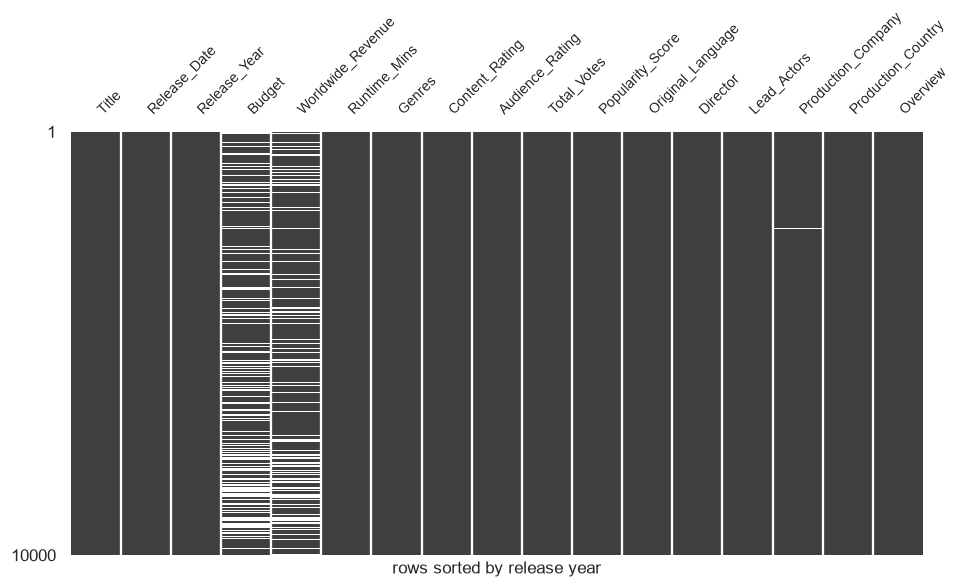

In [6]:
ax = msno.matrix(df.sort_values("Release_Year"), fontsize=9, sparkline=False)
ax.set_xlabel("rows sorted by release year")
fig = plt.gcf()
fig.set_size_inches(10, 5)
save_fig(fig, "fig2_1_missing_matrix")
plt.show()

Rows are sorted by release year, so the vertical gradient in the Budget
column is already a hint: missing financials are not scattered evenly —
they concentrate in particular kinds of films. Tested formally below.

## Step 3 — implausible values

Financial figures from \$1 to \$999 are entry errors or thousands-scale
figures; a runtime of 0 minutes is impossible; the literal director name
`"Name"` is a scraping placeholder. All become NaN. No rows are dropped.

In [7]:
df, floor_counts = clean.floor_financials(df)
df, n_runtime = clean.clean_runtime(df)
df, n_director = clean.fix_director_placeholder(df)
log["budget_floored"] = floor_counts["Budget"]
log["revenue_floored"] = floor_counts["Worldwide_Revenue"]
log["runtime_zeroed"] = n_runtime
log["director_placeholder"] = n_director
print(f"budgets in [1, 999] -> NaN:  {floor_counts['Budget']}")
print(f"revenues in [1, 999] -> NaN: {floor_counts['Worldwide_Revenue']}")
print(f"zero runtimes -> NaN:        {n_runtime}")
print(f"director 'Name' -> NaN:      {n_director}")

budgets in [1, 999] -> NaN:  13
revenues in [1, 999] -> NaN: 9
zero runtimes -> NaN:        1
director 'Name' -> NaN:      1


## Step 4 — duplicates

Four rows are exact copies of another row and are dropped. The remaining
films that share a title and year are *different films* — different
directors, runtimes, languages — so title+year is **not** used as a
dedupe key. The table shows why.

In [8]:
dup_pairs = df[df.duplicated(subset=["Title", "Release_Year"], keep=False) & ~df.duplicated(keep=False)]
dup_pairs.sort_values(["Title", "Release_Year"])[
    ["Title", "Release_Year", "Director", "Runtime_Mins", "Original_Language"]
]

,Title,Release_Year,Director,Runtime_Mins,Original_Language
7490,Return,1972,Arman Manaryan,82.0,hy
9168,Return,1972,David Greig,6.0,en
4410,Return,2015,Haqi Ali,45.0,en
5010,Return,2015,Jon Hyatt,17.0,en
6916,Return,2015,Ryan Heron,15.0,en
7464,Return,2023,Katja Fedulova,61.0,tt
9312,Return,2023,Pete Tolton,92.0,en
6823,Return,<NA>,NaN,18.0,en
8790,Return,<NA>,Malou Reymann,15.0,en
9075,Return,<NA>,Selman Deniz,18.0,hy


In [9]:
df, n_dups = clean.drop_exact_duplicates(df)
log["exact_duplicates_dropped"] = n_dups
log["rows_after_dedupe"] = len(df)
print(f"exact duplicate rows dropped: {n_dups}  ->  {len(df):,} rows remain")

exact duplicate rows dropped: 4  ->  9,996 rows remain


## Step 5 — category hygiene

In [10]:
df, cr_counts = clean.clean_content_rating(df)
df, n_country = clean.normalise_countries(df)
log["content_rating_ws_fixed"] = cr_counts["whitespace_fixed"]
log["content_rating_nr_merged"] = cr_counts["nr_merged"]
log["country_rows_renamed"] = n_country
df["Content_Rating"].value_counts(dropna=False)

Content_Rating
R          4015
PG-13      2370
Unrated    1857
PG         1301
G           405
NC-17        48
Name: count, dtype: int64

## Step 6 — flag unreleased films

Films dated after 2025 cannot have complete revenue. They stay in the
dataset for descriptive counts but are excluded from every financial
analysis via the `is_future` flag.

In [11]:
df, n_future = clean.flag_future(df)
log["future_flagged"] = n_future
print(f"films flagged is_future (year > 2025): {n_future}")

films flagged is_future (year > 2025): 92


## Step 7 — is the missingness random? (MCAR vs MAR)

If financials were missing completely at random, documented and
undocumented films would look alike on every other variable, and median
imputation would be defensible. Compare the two groups on year, votes,
rating, popularity and language. Distributions are heavily skewed, so the
test is Mann-Whitney U (nonparametric), with the rank-biserial correlation
as effect size; language uses a chi-square test on the 2x2 table.

In [12]:
df, n_has_fin = clean.flag_has_financials(df)
log["has_financials"] = n_has_fin

# Released films only: post-2025 films lack revenue for a different reason
# (it does not exist yet) and would bias the comparison toward "newer".
mar = df[~df["is_future"]]
grp = mar["has_financials"]
log["mar_n_doc"] = int(grp.sum())
log["mar_n_undoc"] = int((~grp).sum())
compare_cols = ["Release_Year", "Total_Votes", "Audience_Rating", "Popularity_Score"]

rows = []
for col in compare_cols:
    a = mar.loc[grp, col].dropna().astype("float64")
    b = mar.loc[~grp, col].dropna().astype("float64")
    u, p = sps.mannwhitneyu(a, b, alternative="two-sided")
    rank_biserial = 1 - 2 * u / (len(a) * len(b))
    rows.append(
        {
            "variable": col,
            "median documented": a.median(),
            "median undocumented": b.median(),
            "Mann-Whitney p": p,
            "rank-biserial r": round(rank_biserial, 3),
            "n doc": len(a),
            "n undoc": len(b),
        }
    )
mar_table = pd.DataFrame(rows).set_index("variable")
log["mar_p_year"] = float(mar_table.loc["Release_Year", "Mann-Whitney p"])
log["mar_p_votes"] = float(mar_table.loc["Total_Votes", "Mann-Whitney p"])
log["mar_median_votes_doc"] = float(mar_table.loc["Total_Votes", "median documented"])
log["mar_median_votes_undoc"] = float(mar_table.loc["Total_Votes", "median undocumented"])
log["mar_median_year_doc"] = float(mar_table.loc["Release_Year", "median documented"])
log["mar_median_year_undoc"] = float(mar_table.loc["Release_Year", "median undocumented"])
log["mar_median_pop_doc"] = float(mar_table.loc["Popularity_Score", "median documented"])
log["mar_median_pop_undoc"] = float(mar_table.loc["Popularity_Score", "median undocumented"])
log["mar_median_rating_doc"] = float(mar_table.loc["Audience_Rating", "median documented"])
log["mar_median_rating_undoc"] = float(mar_table.loc["Audience_Rating", "median undocumented"])
log["mar_p_rating"] = float(mar_table.loc["Audience_Rating", "Mann-Whitney p"])
mar_table

,median documented,median undocumented,Mann-Whitney p,rank-biserial r,n doc,n undoc
variable,,,,,,
Release_Year,2007.0000,2015.00000,6.823870e-90,0.247,6560,3341
Total_Votes,1494.0000,608.00000,0.000000e+00,-0.547,6560,3344
Audience_Rating,6.6955,6.70000,1.024527e-01,0.020,6560,3344
Popularity_Score,7.5198,4.74105,0.000000e+00,-0.515,6560,3344


In [13]:
# Language: is a documented film more likely to be in English?
ct = pd.crosstab(mar["Original_Language"] == "en", grp)
chi2, p_lang, dof, _ = sps.chi2_contingency(ct)
pct_en_doc = (mar.loc[grp, "Original_Language"] == "en").mean() * 100
pct_en_undoc = (mar.loc[~grp, "Original_Language"] == "en").mean() * 100
log["mar_p_language"] = float(p_lang)
log["mar_pct_english_doc"] = round(float(pct_en_doc), 1)
log["mar_pct_english_undoc"] = round(float(pct_en_undoc), 1)
print(f"English share, documented:   {pct_en_doc:.1f}%")
print(f"English share, undocumented: {pct_en_undoc:.1f}%")
print(f"chi-square p = {p_lang:.2e}")

# One table for the report: four Mann-Whitney rows plus the language chi-square row
mar_tex = pd.DataFrame(
    {
        "variable": ["release year", "total votes", "audience rating", "popularity score"],
        "median (known)": [f"{v:.0f}" if i == 0 else fmt_int(v) if i == 1 else f"{v:.2f}"
                           for i, v in enumerate(mar_table["median documented"])],
        "median (missing)": [f"{v:.0f}" if i == 0 else fmt_int(v) if i == 1 else f"{v:.2f}"
                             for i, v in enumerate(mar_table["median undocumented"])],
        "test": ["Mann-Whitney U"] * 4,
        "p": [fmt_p(p) for p in mar_table["Mann-Whitney p"]],
        "effect r": [f"{v:+.2f}" for v in mar_table["rank-biserial r"]],
    }
)
mar_tex.loc[len(mar_tex)] = ["% English-language", f"{pct_en_doc:.1f}", f"{pct_en_undoc:.1f}",
                             "chi-square", fmt_p(p_lang), "--"]
write_table(mar_tex, "tab2_3_mar_tests", align="lrrlrr")

English share, documented:   88.3%
English share, undocumented: 63.0%
chi-square p = 2.69e-193


WindowsPath('C:/EDA_Project/movie-success-eda/report/tables/tab2_3_mar_tests.tex')

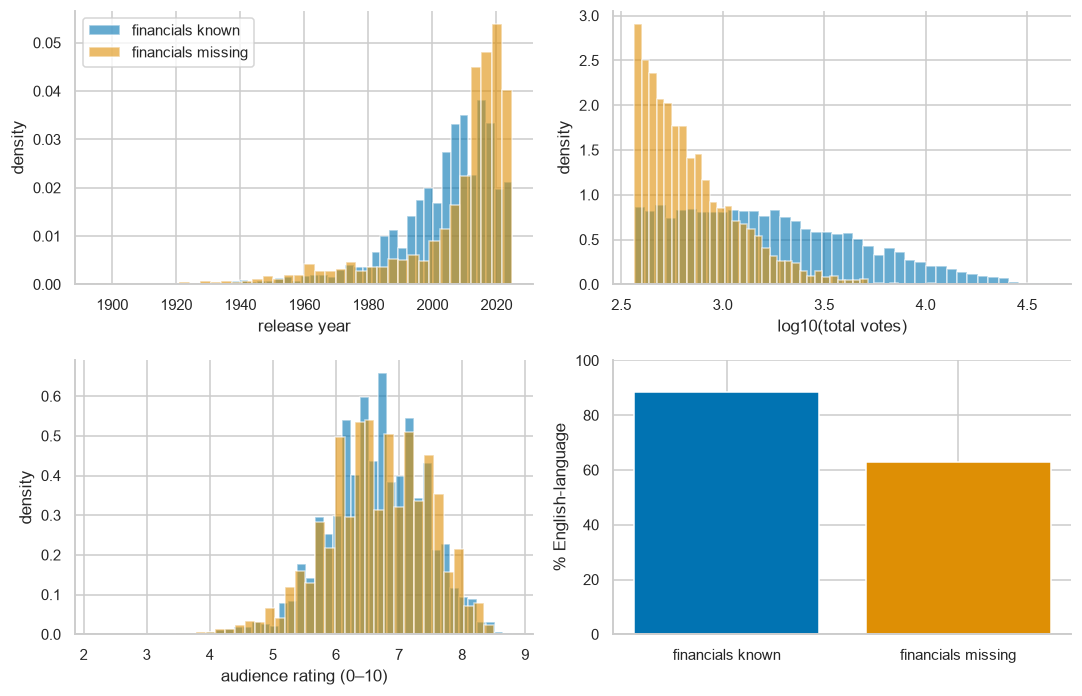

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6.5))
labels = {True: "financials known", False: "financials missing"}
colors = {True: "C0", False: "C1"}

for flag in [True, False]:
    sub = mar[grp == flag]
    axes[0, 0].hist(
        sub["Release_Year"].dropna().astype("float64"), bins=40, alpha=0.6,
        density=True, label=labels[flag], color=colors[flag],
    )
    axes[0, 1].hist(
        np.log10(sub["Total_Votes"]), bins=40, alpha=0.6, density=True, color=colors[flag],
    )
    axes[1, 0].hist(
        sub["Audience_Rating"], bins=40, alpha=0.6, density=True, color=colors[flag],
    )
axes[0, 0].set_xlabel("release year")
axes[0, 0].set_ylabel("density")
axes[0, 0].legend()
axes[0, 1].set_xlabel("log10(total votes)")
axes[0, 1].set_ylabel("density")
axes[1, 0].set_xlabel("audience rating (0–10)")
axes[1, 0].set_ylabel("density")

en_share = pd.DataFrame(
    {
        "group": ["financials known", "financials missing"],
        "pct_english": [pct_en_doc, pct_en_undoc],
    }
)
axes[1, 1].bar(en_share["group"], en_share["pct_english"], color=["C0", "C1"])
axes[1, 1].set_ylabel("% English-language")
axes[1, 1].set_ylim(0, 100)

fig.tight_layout()
save_fig(fig, "fig2_2_mar_comparison")
plt.show()

**Decision.** (Numbers in the table above and in `ch02_cleaning.json`.)
Films with missing financials are far less voted-on, less popular and
much less likely to be in English — and they are **newer**, not older.
That contradicts the project brief's expectation that undocumented films
skew old: the gap is driven by recent, small, often non-English or
streaming-era releases whose box office is never published. Audience
rating is the one variable on which the groups do *not* differ
significantly — what is missing is commercial visibility, not quality.

The missingness is therefore not MCAR; it is at best MAR (explained by
votes, popularity, language and year) and plausibly MNAR (films that
earned little are the ones whose figures go unreported). Imputing a
median budget would invent plausible-looking numbers for precisely the
films least like the ones the median came from, so:

- **Complete-case analysis** for everything financial, on the films with
  both budget and revenue known (sample size stated with every statistic).
- **No imputation** of Budget or Worldwide_Revenue, ever.
- Consequence, stated in the report: financial conclusions apply to
  well-documented, mostly mainstream, mostly English-language cinema —
  not to film in general.

## Step 8 — attach the secondary (Kaggle) file

Joined on normalised title + release year. Three permitted uses: recover
the TMDB `id`, cross-validate ratings and popularity, fill the handful of
missing genres and overviews. The two files are never concatenated.

The fill mechanism turns out to fill **nothing**: the three rows with a
missing genre or overview are obscure films all titled "Return" (two of
them with no release year) that do not appear in the Kaggle top-10K file.
The counts below report that honestly rather than pretending the
secondary file rescued them.

In [15]:
df2 = load_secondary()
df, sec_counts = clean.attach_secondary(df, df2)
log.update(
    secondary_matched=sec_counts["matched"],
    genres_filled=sec_counts["genres_filled"],
    overviews_filled=sec_counts["overviews_filled"],
)
print(f"films matched to secondary file: {sec_counts['matched']:,} of {len(df):,}")
print(f"missing genres filled:    {sec_counts['genres_filled']}")
print(f"missing overviews filled: {sec_counts['overviews_filled']}")

films matched to secondary file: 8,417 of 9,996
missing genres filled:    0
missing overviews filled: 0


### Cross-source validation

Do the two collections agree on the films they share? If the scrape is
sound, the primary `Audience_Rating` and the Kaggle `vote_average` should
be nearly identical, and the two popularity scores should rank films
similarly (popularity is time-sensitive, so exact agreement is not expected).

In [16]:
m = df.dropna(subset=["sec_vote_average"])
r_rating_p, p_rating = sps.pearsonr(m["Audience_Rating"], m["sec_vote_average"])
r_rating_s, _ = sps.spearmanr(m["Audience_Rating"], m["sec_vote_average"])
r_pop_s, p_pop = sps.spearmanr(m["Popularity_Score"], m["sec_popularity"])
log.update(
    crossval_n=len(m),
    crossval_rating_pearson=round(float(r_rating_p), 4),
    crossval_rating_spearman=round(float(r_rating_s), 4),
    crossval_popularity_spearman=round(float(r_pop_s), 4),
)
print(f"shared films: {len(m):,}")
print(f"rating    Pearson r  = {r_rating_p:.4f} (p = {p_rating:.2e})")
print(f"rating    Spearman r = {r_rating_s:.4f}")
print(f"popularity Spearman r = {r_pop_s:.4f} (time-sensitive metric)")

shared films: 8,417
rating    Pearson r  = 0.9919 (p = 0.00e+00)
rating    Spearman r = 0.9917
popularity Spearman r = 0.7025 (time-sensitive metric)


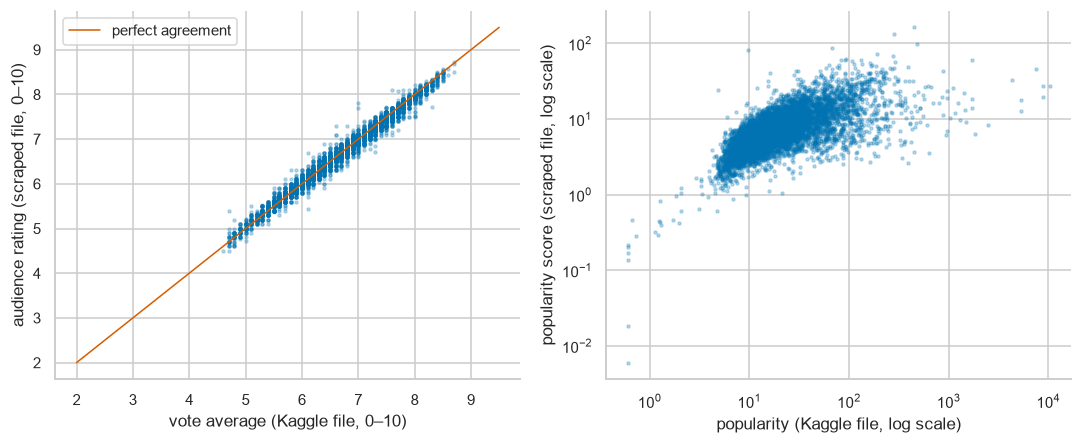

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
axes[0].scatter(m["sec_vote_average"], m["Audience_Rating"], s=4, alpha=0.25)
axes[0].plot([2, 9.5], [2, 9.5], color="C3", lw=1, label="perfect agreement")
axes[0].set_xlabel("vote average (Kaggle file, 0–10)")
axes[0].set_ylabel("audience rating (scraped file, 0–10)")
axes[0].legend()
axes[1].scatter(m["sec_popularity"], m["Popularity_Score"], s=4, alpha=0.25)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("popularity (Kaggle file, log scale)")
axes[1].set_ylabel("popularity score (scraped file, log scale)")
fig.tight_layout()
save_fig(fig, "fig2_3_crossval")
plt.show()

## Step 9 — inflation adjustment

Nominal dollars across 1895–2026 are not comparable. Both financial
columns are deflated to constant **2025 dollars** with the annual-average
US CPI-U (FRED series `CPIAUCNS`, committed at
`data/raw/cpi_cpiaucns_monthly.csv`). CPI starts in 1913: earlier films
get no deflated value rather than an invented factor, and so do post-2025
films (partial-year CPI, excluded from financial analysis anyway).

In [18]:
cpi = clean.cpi_annual(RAW / "cpi_cpiaucns_monthly.csv")
df["Budget_2025usd"] = clean.deflate(df["Budget"], df["Release_Year"], cpi)
df["Revenue_2025usd"] = clean.deflate(df["Worldwide_Revenue"], df["Release_Year"], cpi)

pre_cpi = int((df["Release_Year"] < 1913).sum())
lost_budget = int((df["Budget"].notna() & df["Budget_2025usd"].isna()).sum())
log["pre_1913_films"] = pre_cpi
log["deflation_lost_budget_values"] = lost_budget
print(f"films before 1913 (no CPI):                  {pre_cpi}")
print(f"known budgets without a deflated value:      {lost_budget}")
lost_usable = int(
    (df["has_financials"] & ~df["is_future"] & df["Budget_2025usd"].isna()).sum()
)
log["deflation_lost_usable"] = lost_usable
print(f"…of which in the usable financial sample:    {lost_usable}")

films before 1913 (no CPI):                  4
known budgets without a deflated value:      64
…of which in the usable financial sample:    0


In [19]:
# Sanity check on familiar titles: nominal vs constant-2025 dollars
chk = df[df["Title"].isin(["Jaws", "Titanic", "Oppenheimer"])].dropna(subset=["Budget"])
chk = chk[["Title", "Release_Year", "Budget", "Budget_2025usd"]].sort_values("Release_Year")
for _, r in chk.iterrows():
    key = r["Title"].lower().replace(" ", "")
    log[f"deflate_{key}_nominal_m"] = round(float(r["Budget"]) / 1e6, 1)
    log[f"deflate_{key}_2025_m"] = round(float(r["Budget_2025usd"]) / 1e6, 1)
log["cpi_base_year"] = clean.CPI_BASE_YEAR
chk.assign(
    Budget=lambda d: (d["Budget"] / 1e6).round(1),
    Budget_2025usd=lambda d: (d["Budget_2025usd"] / 1e6).round(1),
).rename(columns={"Budget": "budget ($M nominal)", "Budget_2025usd": "budget ($M, 2025)"})

,Title,Release_Year,budget ($M nominal),"budget ($M, 2025)"
271,Jaws,1975,7.0,41.9
16,Titanic,1997,200.0,401.1
247,Oppenheimer,2023,100.0,105.7


## Step 10 — reconciliation and output

10,000 rows in; only exact duplicates leave. Everything else is flagged
or NaN'd and excluded per-analysis, never dropped from the file.

In [20]:
usable = df["has_financials"] & ~df["is_future"]
log["rows_out"] = len(df)
log["usable_financial_sample"] = int(usable.sum())

recon = pd.DataFrame(
    [
        ["rows in (raw file)", log["rows_in"]],
        ["exact duplicate rows dropped", -log["exact_duplicates_dropped"]],
        ["rows out (cleaned file)", log["rows_out"]],
        ["  … with budget & revenue known", log["has_financials"]],
        ["  … and released (not future)", log["usable_financial_sample"]],
    ],
    columns=["step", "rows"],
)
recon_tex = recon.copy()
recon_tex["step"] = (
    recon_tex["step"].str.replace("&", "and", regex=False).str.replace("  … ", r"$\quad$ ", regex=False)
)
recon_tex["rows"] = recon_tex["rows"].map(lambda v: ("$-$" + fmt_int(-v)) if v < 0 else fmt_int(v))
write_table(recon_tex, "tab2_4_reconciliation")
recon

,step,rows
0,rows in (raw file),10000
1,exact duplicate rows dropped,-4
2,rows out (cleaned file),9996
3,… with budget & revenue known,6619
4,… and released (not future),6560


In [21]:
INTERIM.mkdir(parents=True, exist_ok=True)
df.to_parquet(INTERIM / "movies_clean.parquet")
out = write_stats("ch02_cleaning", log)
print(f"wrote {INTERIM / 'movies_clean.parquet'}")
print(f"{len(log)} statistics -> {out.relative_to(ROOT)}")

wrote C:\EDA_Project\movie-success-eda\data\interim\movies_clean.parquet
49 statistics -> report\stats\ch02_cleaning.json


## Chapter 2 summary

| Rule | Effect |
|---|---|
| Zero-coded financials -> NaN | 2,814 budgets, 2,288 revenues |
| Floor at \$1,000 | 13 budgets, 9 revenues -> NaN |
| Zero runtime, placeholder director | 1 each -> NaN |
| Exact duplicates | 4 rows dropped (only rows removed) |
| Title+year "duplicates" | kept — verified distinct films |
| `NR` -> `Unrated`, whitespace stripped | one consistent rating scheme |
| `is_future` flag | post-2025 films excluded from financial analysis |
| MCAR/MAR test | missingness strongly non-random -> complete-case, no imputation |
| Secondary join | TMDB id recovered; ratings cross-validated; genres/overviews filled |
| CPI deflation | constant-2025-dollar budget and revenue columns |

The financial analysis sample is **`usable_financial_sample`** films
(budget and revenue known, released by 2025) out of 9,996 — every other
film remains for non-financial analysis.